In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("../data/sales.csv")

In [5]:
df.head()

,order_id,date,product,category,quantity,unit_price,region
0,1001,2026-01-05,Laptop,Electronics,2,850,North
1,1002,2026-01-07,Mouse,Accessories,5,20,South
2,1003,2026-01-10,Keyboard,Accessories,3,45,East
3,1004,2026-01-15,Monitor,Electronics,2,220,West
4,1005,2026-01-18,Laptop,Electronics,1,850,East


In [6]:
df.shape

(20, 7)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    20 non-null     int64
 1   date        20 non-null     str  
 2   product     20 non-null     str  
 3   category    20 non-null     str  
 4   quantity    20 non-null     int64
 5   unit_price  20 non-null     int64
 6   region      20 non-null     str  
dtypes: int64(3), str(4)
memory usage: 1.2 KB


In [8]:
df.describe()

,order_id,quantity,unit_price
count,20.00000,20.00000,20.000000
mean,1010.50000,3.55000,255.000000
std,5.91608,2.48098,313.440165
min,1001.00000,1.00000,20.000000
25%,1005.75000,2.00000,45.000000
50%,1010.50000,3.00000,137.500000
75%,1015.25000,4.25000,220.000000
max,1020.00000,10.00000,850.000000


In [9]:
df.columns

Index(['order_id', 'date', 'product', 'category', 'quantity', 'unit_price',
       'region'],
      dtype='str')

In [10]:
df.dtypes

order_id      int64
date            str
product         str
category        str
quantity      int64
unit_price    int64
region          str
dtype: object

In [11]:
df.isnull().sum()

order_id      0
date          0
product       0
category      0
quantity      0
unit_price    0
region        0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.describe()

,order_id,quantity,unit_price
count,20.00000,20.00000,20.000000
mean,1010.50000,3.55000,255.000000
std,5.91608,2.48098,313.440165
min,1001.00000,1.00000,20.000000
25%,1005.75000,2.00000,45.000000
50%,1010.50000,3.00000,137.500000
75%,1015.25000,4.25000,220.000000
max,1020.00000,10.00000,850.000000


In [14]:
df["order_id"].duplicated().sum()

np.int64(0)

In [15]:
df["revenue"] = df["quantity"]*df["unit_price"]

In [16]:
df.head()

,order_id,date,product,category,quantity,unit_price,region,revenue
0,1001,2026-01-05,Laptop,Electronics,2,850,North,1700
1,1002,2026-01-07,Mouse,Accessories,5,20,South,100
2,1003,2026-01-10,Keyboard,Accessories,3,45,East,135
3,1004,2026-01-15,Monitor,Electronics,2,220,West,440
4,1005,2026-01-18,Laptop,Electronics,1,850,East,850


In [17]:
total_revenue = df["revenue"].sum()
print(f"total revenue : ${total_revenue:,.2f}")

total revenue : $10,430.00


In [18]:
average_revenue = df["revenue"].mean()

print(f"average revenue : ${average_revenue:,.2f}")

average revenue : $521.50


In [19]:
highest_revenue = df["revenue"].max()
lowest_revenue = df["revenue"].min()

print("highest revenue :",highest_revenue)
print("lowest revenue:", lowest_revenue)

highest revenue : 2550
lowest revenue: 100


In [20]:
product_revenue = df.groupby("product")["revenue"].sum()

product_revenue

product
Chair        855
Desk         900
Keyboard     585
Laptop      5950
Monitor     1540
Mouse        600
Name: revenue, dtype: int64

In [21]:
best_product = product_revenue.idxmax()

print("best product:", best_product)

best product: Laptop


In [22]:
product_quantity = df.groupby("product")["quantity"].sum()
product_quantity

product
Chair        9
Desk         5
Keyboard    13
Laptop       7
Monitor      7
Mouse       30
Name: quantity, dtype: int64

In [23]:
category_revenue = df.groupby("category")["revenue"].sum()
category_revenue

category
Accessories    1185
Electronics    7490
Furniture      1755
Name: revenue, dtype: int64

In [24]:
best_category = category_revenue.idxmax()
print("best category", best_category)

best category Electronics


In [25]:
df["date"] = pd.to_datetime(df["date"])

In [27]:
df["month"] = df["date"].dt.month

In [29]:
monthly_revenue = df.groupby("month")["revenue"].sum()
monthly_revenue

month
1    3225
2    1830
3    3560
4    1815
Name: revenue, dtype: int64

In [30]:
best_month = monthly_revenue.idxmax()
print("best month :",best_month)

best month : 3


In [31]:
region_revenue = df.groupby("region")["revenue"].sum()
region_revenue

region
East     1740
North    3550
South    1230
West     3910
Name: revenue, dtype: int64

In [32]:
best_region = region_revenue.idxmax()
print("best region :", best_region)

best region : West


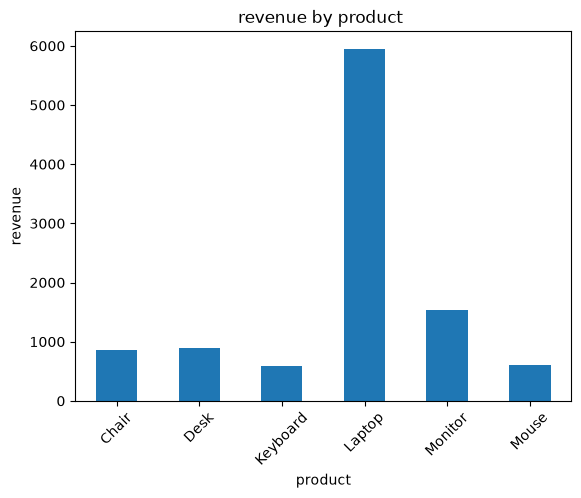

In [33]:
import matplotlib.pyplot as plt

product_revenue.plot(kind = "bar")

plt.title("revenue by product ")
plt.xlabel("product")
plt.ylabel("revenue")
plt.xticks(rotation = 45)

plt.show()

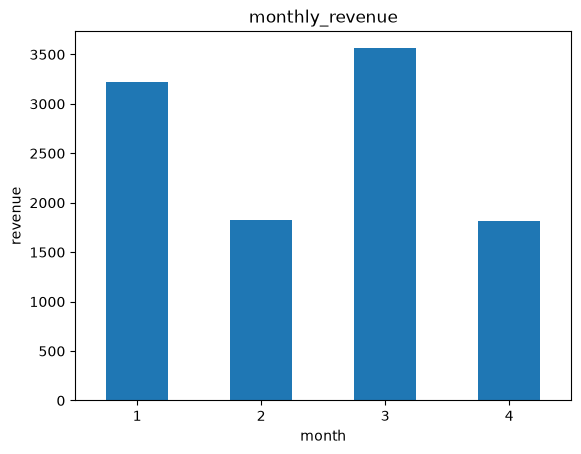

In [34]:
monthly_revenue.plot(kind = "bar")

plt.title("monthly_revenue")
plt.xlabel("month")
plt.ylabel("revenue")
plt.xticks(rotation = 0)

plt.show()